
=== RESULTADOS DO DIMENSIONAMENTO (BOOST) ===
Tensão de saída (Vo): 60.00 V
Resistência de carga: 40.00 Ω
Potência máxima dissipada na carga: 90.00 W
Indutor de saída (Lo): 0.001250000000 H
Capacitor de saída (Co): 0.000062500000 F


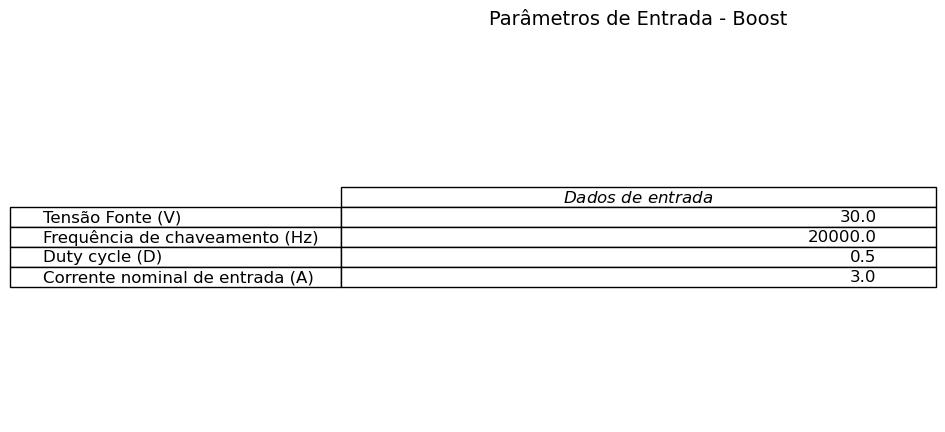

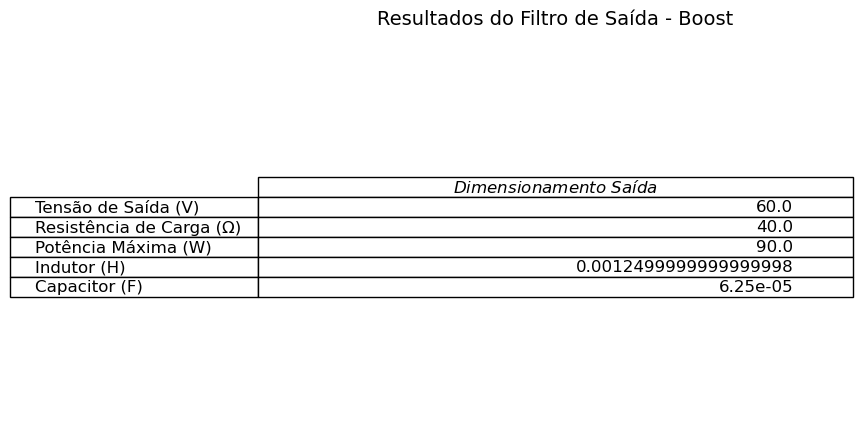

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------------------------------------------------
# 1. Entrada de Dados de Projeto (Conversor Boost)
# -----------------------------------------------------------------------------
Vs = float(input("Digite o valor de tensão na entrada (V): "))
f = float(input("Digite a frequência de chaveamento (Hz): "))
d = float(input("Digite o ciclo de trabalho (0-1): "))
i_in = float(input("Digite a corrente nominal de entrada (A): "))

# -----------------------------------------------------------------------------
# 2. Cálculos das Grandezas Elétricas do Boost
# -----------------------------------------------------------------------------
# Tensão nominal de saída no Boost: Vo = Vs / (1 - d)
Vo = Vs / (1 - d)

# Potência máxima de entrada/saída (considerando conversor ideal): Pmáx = Vs * I_in
Pmáx = Vs * i_in

# Corrente nominal de saída: Io = Pmáx / Vo
Io = Pmáx / Vo

# Resistência de carga na saída
R = (Vo**2) / Pmáx

print("\n=== RESULTADOS DO DIMENSIONAMENTO (BOOST) ===")
print(f"Tensão de saída (Vo): {Vo:.2f} V")
print(f"Resistência de carga: {R:.2f} Ω")
print(f"Potência máxima dissipada na carga: {Pmáx:.2f} W")

# -----------------------------------------------------------------------------
# 3. Parametrização dos Elementos Reativos (Indutor e Capacitor)
# -----------------------------------------------------------------------------
# Ondulação de corrente no indutor: 20% da corrente nominal de entrada
delta_I = 0.20 * i_in

# Ondulação de tensão no capacitor: 1% da tensão nominal de saída
delta_Vc = 0.01 * Vo

# Indutor de entrada/saída (Lo)
Lo = (Vs * d) / (f * delta_I)
print(f"Indutor de saída (Lo): {Lo:.12f} H")

# Capacitor de saída (Co)
Co = (Io * d) / (f * delta_Vc)
print(f"Capacitor de saída (Co): {Co:.12f} F")

# -----------------------------------------------------------------------------
# 4. Exibição da Tabela 1 - Dados de Entrada
# -----------------------------------------------------------------------------
col_labels = [r"$Dados\ de\ entrada$"]
row_labels = [
    "Tensão Fonte (V)",
    "Frequência de chaveamento (Hz)",
    "Duty cycle (D)",
    "Corrente nominal de entrada (A)",
]
table_vals = [[Vs], [f], [d], [i_in]]

fig, ax = plt.subplots()
ax.axis("tight")
ax.axis("off")

table = ax.table(
    cellText=table_vals,
    colLabels=col_labels,
    rowLabels=row_labels,
    loc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.2)
plt.title("Parâmetros de Entrada - Boost", fontsize=14, pad=20)
plt.show()

# -----------------------------------------------------------------------------
# 5. Exibição da Tabela 2 - Dimensionamento de Saída
# -----------------------------------------------------------------------------
col_labels = [r"$Dimensionamento\ Saída$"]
row_labels = [
    "Tensão de Saída (V)",
    "Resistência de Carga (Ω)",
    "Potência Máxima (W)",
    "Indutor (H)",
    "Capacitor (F)",
]
table_vals = [[Vo], [R], [Pmáx], [Lo], [Co]]

fig, ax = plt.subplots()
ax.axis("tight")
ax.axis("off")

table = ax.table(
    cellText=table_vals,
    colLabels=col_labels,
    rowLabels=row_labels,
    loc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.2)
plt.title("Resultados do Filtro de Saída - Boost", fontsize=14, pad=20)
plt.show()